In [ ]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import random
import pandas as pd
SEED = 0
np.random.seed(SEED)
random.seed(SEED)


my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)


from matplotlib import font_manager

font_dir = "/users/PAS2148/tiger/.local/share/fonts/arial"
for f in font_manager.findSystemFonts(fontpaths=[font_dir]):
    font_manager.fontManager.addfont(f)

plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False

figure_save_path = "Supplementary_Fig_2_figures"
os.makedirs(figure_save_path, exist_ok=True)




In [12]:
filtered_ipf_ul_dict = pd.read_excel("/fs/ess/PAS2148/huchen/fibroblasts_data/Lung_tissue_IPF_UL_vs_Aged_control_selected_Pathway.xlsx", sheet_name=None)


## Supplementary Fig. 2d  

In [13]:
filtered_terms = ['Collagen Biosynthetic Process',
 'Collagen Fibril Organization',
 'Extracellular Structure Organization',
 'Extracellular Matrix Organization',
 'Extracellular Matrix Disassembly',
 'Regulation of Fatty Acid Oxidation',
 'Muscle Organ Development'
                 ]

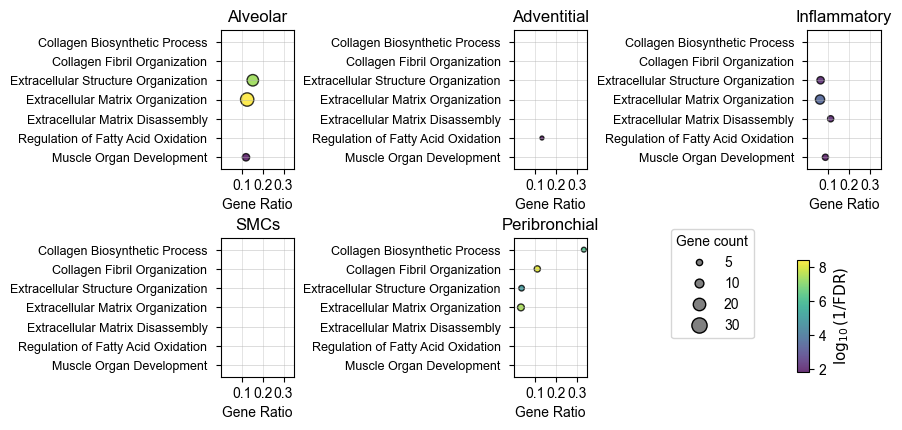

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

cell_types = list(filtered_ipf_ul_dict.keys())
n_rows, n_cols = 2, 3
fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(12, 4.5),
    gridspec_kw={
        "left": 0.40,
        "right": 0.95,
        "wspace": 3,
        "hspace": 0.5,
    }
)
axes = axes.flatten()

all_vals_list = []
for ct in cell_types:
    df_ct = filtered_ipf_ul_dict[ct]
    sig_mask = df_ct["Adjusted P-value"] < 0.05
    all_vals_list.append(df_ct.loc[sig_mask, "log10_1_over_FDR"])
all_vals = pd.concat(all_vals_list)
vmin, vmax = all_vals.min(), all_vals.max()

last_scatter = None

term_order = filtered_terms[::-1]

term_to_y = {term: idx for idx, term in enumerate(term_order)}

for i, ct in enumerate(cell_types):
    if i >= n_rows * n_cols:
        break
    ax = axes[i]

    df_raw = filtered_ipf_ul_dict[ct].copy()

    df_terms = pd.DataFrame({"Term": filtered_terms})
    df = df_terms.merge(df_raw, on="Term", how="left")

    overlap_split = df["Overlap"].str.split("/", expand=True)
    df["Gene_count"] = overlap_split[0].astype(float)
    df["Pathway_size"] = overlap_split[1].astype(float)
    df["Gene_count"] = df["Gene_count"].fillna(0).astype(int)
    df["Gene_ratio"] = (df["Gene_count"] / df["Pathway_size"]).fillna(0)

    sig_mask = df["Adjusted P-value"].notna() & (df["Adjusted P-value"] < 0.05)

    df["Gene_count_plot"] = np.where(sig_mask, df["Gene_count"], 0)
    df["Gene_ratio_plot"] = np.where(sig_mask, df["Gene_ratio"], 0)

    df["log10_1_over_FDR_plot"] = np.where(
        sig_mask,
        df["log10_1_over_FDR"],
        np.nan
    )

    df["y_pos"] = df["Term"].map(term_to_y)

    sc = ax.scatter(
        df["Gene_ratio_plot"],
        df["y_pos"],
        c=df["log10_1_over_FDR_plot"],
        s=df["Gene_count_plot"] * 4,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        alpha=0.8,
        edgecolor="black"
    )
    ax.grid(which='major', axis='y', linewidth=0.6, alpha=0.5)
    ax.grid(which='major', axis='x', linewidth=0.6, alpha=0.4)
    ax.set_ylim(-0.6, len(term_order)-0.4)
    ax.margins(y=0.1)

    last_scatter = sc

    ax.set_xlim(0, 0.35)
    ax.set_xticks([0.1, 0.2, 0.3])
    ax.set_xlabel("Gene Ratio")

    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)

    ax.set_yticks(range(len(term_order)))
    ax.set_yticklabels(term_order)
    ax.set_title(ct)
    ax.tick_params(axis='y', pad=6, labelsize=9)
    ax.set_ylabel("")

for j in range(i + 1, n_rows * n_cols):
    fig.delaxes(axes[j])

cbar_ax = fig.add_axes([0.88, 0.12, 0.01, 0.25])
cbar = fig.colorbar(last_scatter, cax=cbar_ax)
cbar.set_label(r"$\log_{10}(1/\mathrm{FDR})$", fontsize=11)

sizes = [5, 10, 20, 30]
markers = []
for s in sizes:
    markers.append(Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=np.sqrt(s * 4),
        linestyle='None'
    ))

fig.legend(
    markers,
    [str(s) for s in sizes],
    title="Gene count",
    loc="lower right",
    bbox_to_anchor=(0.85, 0.18)
)


fig.savefig(
    os.path.join(figure_save_path, "combined_pathway_IPF_UL_versus_Aged_Control.pdf"),
    bbox_inches='tight'
)

plt.show()

## Supplementary Fig. 2e

In [15]:
filtered_ipf_ll_dict = pd.read_excel("/fs/ess/PAS2148/huchen/fibroblasts_data/Lung_tissue_IPF_LL_vs_Aged_control_selected_Pathway.xlsx", sheet_name=None)


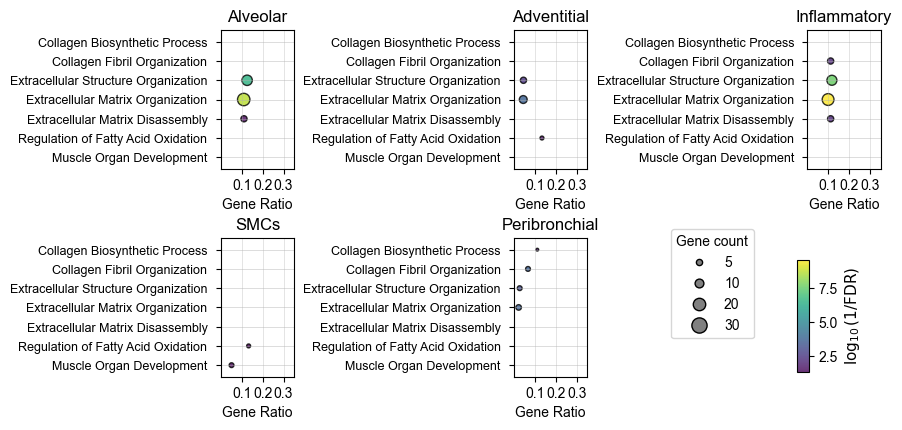

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

cell_types = list(filtered_ipf_ll_dict.keys())
n_rows, n_cols = 2, 3
fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(12, 4.5),
    gridspec_kw={
        "left": 0.40,
        "right": 0.95,
        "wspace": 3,
        "hspace": 0.5,
    }
)
axes = axes.flatten()

all_vals_list = []
for ct in cell_types:
    df_ct = filtered_ipf_ll_dict[ct]
    sig_mask = df_ct["Adjusted P-value"] < 0.05
    all_vals_list.append(df_ct.loc[sig_mask, "log10_1_over_FDR"])
all_vals = pd.concat(all_vals_list)
vmin, vmax = all_vals.min(), all_vals.max()

last_scatter = None

term_order = filtered_terms[::-1]

term_to_y = {term: idx for idx, term in enumerate(term_order)}

for i, ct in enumerate(cell_types):
    if i >= n_rows * n_cols:
        break
    ax = axes[i]

    df_raw = filtered_ipf_ll_dict[ct].copy()

    df_terms = pd.DataFrame({"Term": filtered_terms})
    df = df_terms.merge(df_raw, on="Term", how="left")

    overlap_split = df["Overlap"].str.split("/", expand=True)
    df["Gene_count"] = overlap_split[0].astype(float)
    df["Pathway_size"] = overlap_split[1].astype(float)
    df["Gene_count"] = df["Gene_count"].fillna(0).astype(int)
    df["Gene_ratio"] = (df["Gene_count"] / df["Pathway_size"]).fillna(0)

    sig_mask = df["Adjusted P-value"].notna() & (df["Adjusted P-value"] < 0.05)

    df["Gene_count_plot"] = np.where(sig_mask, df["Gene_count"], 0)
    df["Gene_ratio_plot"] = np.where(sig_mask, df["Gene_ratio"], 0)

    df["log10_1_over_FDR_plot"] = np.where(
        sig_mask,
        df["log10_1_over_FDR"],
        np.nan
    )

    df["y_pos"] = df["Term"].map(term_to_y)

    sc = ax.scatter(
        df["Gene_ratio_plot"],
        df["y_pos"],
        c=df["log10_1_over_FDR_plot"],
        s=df["Gene_count_plot"] * 4,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        alpha=0.8,
        edgecolor="black"
    )
    ax.set_ylim(-0.6, len(term_order)-0.4)

    ax.grid(which='major', axis='y', linewidth=0.6, alpha=0.5)
    ax.grid(which='major', axis='x', linewidth=0.6, alpha=0.4)
    
    ax.margins(y=0.1)

    last_scatter = sc

    ax.set_xlim(0, 0.35)
    ax.set_xticks([0.1, 0.2, 0.3])
    ax.set_xlabel("Gene Ratio")

    # ax.spines['top'].set_visible(False)
    # ax.spines['right'].set_visible(False)

    ax.set_yticks(range(len(term_order)))
    ax.set_yticklabels(term_order)
    ax.set_title(ct)
    ax.tick_params(axis='y', pad=6, labelsize=9)
    ax.set_ylabel("")

for j in range(i + 1, n_rows * n_cols):
    fig.delaxes(axes[j])

cbar_ax = fig.add_axes([0.88, 0.12, 0.01, 0.25])
cbar = fig.colorbar(last_scatter, cax=cbar_ax)
cbar.set_label(r"$\log_{10}(1/\mathrm{FDR})$", fontsize=11)

sizes = [5, 10, 20, 30]
markers = []
for s in sizes:
    markers.append(Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markeredgecolor='black',
        markersize=np.sqrt(s * 4),
        linestyle='None'
    ))

fig.legend(
    markers,
    [str(s) for s in sizes],
    title="Gene count",
    loc="lower right",
    bbox_to_anchor=(0.85, 0.18)
)


fig.savefig(
    os.path.join(figure_save_path, "combined_pathway_IPF_LL_versus_Aged_Control.pdf"),
    bbox_inches='tight'
)

plt.show()